# Machine Learning Assignment – 2

## Online Shoppers Purchasing Intention Prediction

**Programme:** M.Tech – Artificial Intelligence and Machine Learning  
**Subject:** Machine Learning

**Name:** Sarth Nitin Khandekar  
**Student ID:** 2025AF05161


### Problem Statement

The objective of this assignment is to develop and compare five machine learning classification algorithms to predict whether an online shopper will generate revenue based on browsing behaviour and session-related attributes.

### Objectives
- Perform exploratory data analysis and preprocessing.
- Implement five classification algorithms.
- Evaluate models using six performance metrics.
- Compare model performance and identify the best-performing classifier.
- Develop an interactive Streamlit application for model evaluation.

In [1]:
import os
import joblib
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

print("All libraries imported successfully.")

All libraries imported successfully.


In [2]:
import pandas as pd
import os

file_path = r"C:\Users\Sarth Khandekar\Downloads\online_shoppers_intention.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)
print("Total records:", len(df))
print("Total columns:", len(df.columns))

Dataset loaded successfully.
Dataset shape: (12330, 18)
Total records: 12330
Total columns: 18


In [3]:
# Separate input features and target variable
X = df.drop(columns=["Revenue"])
y = df["Revenue"].astype(int)

# Identify numerical and categorical columns
numerical_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "bool"]).columns.tolist()

# Create preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Create folders for saved models and reports
os.makedirs("models", exist_ok=True)
os.makedirs("reports", exist_ok=True)

# Initialize dictionaries to store trained models and results
trained_models = {}
results = []

print("Preprocessing setup completed.")
print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])
print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

Preprocessing setup completed.
Training records: 9864
Testing records: 2466
Numerical features: 14
Categorical features: 3


C:\Users\Sarth Khandekar\AppData\Local\Temp\ipykernel_14552\217008358.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include=["object", "bool"]).columns.tolist()


In [4]:
# Train Logistic Regression model
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

# Make predictions
y_pred = logistic_model.predict(X_test)
y_prob = logistic_model.predict_proba(X_test)[:, 1]

# Evaluate model
metrics = {
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(y_test, y_pred),
    "AUC": roc_auc_score(y_test, y_prob),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1 Score": f1_score(y_test, y_pred, zero_division=0),
    "MCC": matthews_corrcoef(y_test, y_pred)
}

results.append(metrics)
trained_models["Logistic Regression"] = logistic_model

print("Logistic Regression trained successfully.")
print(pd.DataFrame([metrics]).round(4).to_string(index=False))

Logistic Regression trained successfully.
              Model  Accuracy    AUC  Precision  Recall  F1 Score   MCC
Logistic Regression      0.85 0.8962     0.5107  0.7487    0.6072 0.533


In [5]:
# Train Decision Tree model
decision_tree_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=10,
        class_weight="balanced",
        random_state=42
    ))
])

decision_tree_model.fit(X_train, y_train)

# Make predictions
y_pred = decision_tree_model.predict(X_test)
y_prob = decision_tree_model.predict_proba(X_test)[:, 1]

# Evaluate model
metrics = {
    "Model": "Decision Tree",
    "Accuracy": accuracy_score(y_test, y_pred),
    "AUC": roc_auc_score(y_test, y_prob),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1 Score": f1_score(y_test, y_pred, zero_division=0),
    "MCC": matthews_corrcoef(y_test, y_pred)
}

results.append(metrics)
trained_models["Decision Tree"] = decision_tree_model

print("Decision Tree trained successfully.")
print(pd.DataFrame([metrics]).round(4).to_string(index=False))

Decision Tree trained successfully.
        Model  Accuracy    AUC  Precision  Recall  F1 Score    MCC
Decision Tree    0.8418 0.8706     0.4935  0.7984      0.61 0.5412


In [6]:
# Train KNN model
knn_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier(n_neighbors=7))
])

knn_model.fit(X_train, y_train)

# Make predictions
y_pred = knn_model.predict(X_test)
y_prob = knn_model.predict_proba(X_test)[:, 1]

# Evaluate model
metrics = {
    "Model": "K-Nearest Neighbors",
    "Accuracy": accuracy_score(y_test, y_pred),
    "AUC": roc_auc_score(y_test, y_prob),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1 Score": f1_score(y_test, y_pred, zero_division=0),
    "MCC": matthews_corrcoef(y_test, y_pred)
}

results.append(metrics)
trained_models["KNN"] = knn_model

print("KNN trained successfully.")
print(pd.DataFrame([metrics]).round(4).to_string(index=False))

KNN trained successfully.
              Model  Accuracy    AUC  Precision  Recall  F1 Score    MCC
K-Nearest Neighbors    0.8747 0.7998     0.6714  0.3743    0.4807 0.4389


In [7]:
# Train Gaussian Naive Bayes model
naive_bayes_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", GaussianNB())
])

naive_bayes_model.fit(X_train, y_train)

# Make predictions
y_pred = naive_bayes_model.predict(X_test)
y_prob = naive_bayes_model.predict_proba(X_test)[:, 1]

# Evaluate model
metrics = {
    "Model": "Gaussian Naive Bayes",
    "Accuracy": accuracy_score(y_test, y_pred),
    "AUC": roc_auc_score(y_test, y_prob),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1 Score": f1_score(y_test, y_pred, zero_division=0),
    "MCC": matthews_corrcoef(y_test, y_pred)
}

results.append(metrics)
trained_models["Naive Bayes"] = naive_bayes_model

print("Gaussian Naive Bayes trained successfully.")
print(pd.DataFrame([metrics]).round(4).to_string(index=False))

Gaussian Naive Bayes trained successfully.
               Model  Accuracy    AUC  Precision  Recall  F1 Score    MCC
Gaussian Naive Bayes    0.6736 0.7932     0.2937   0.788    0.4279 0.3234


In [8]:
# Train Support Vector Machine model
svm_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", SVC(
        kernel="rbf",
        probability=True,
        class_weight="balanced",
        random_state=42
    ))
])

svm_model.fit(X_train, y_train)

# Make predictions
y_pred = svm_model.predict(X_test)
y_prob = svm_model.predict_proba(X_test)[:, 1]

# Evaluate model
metrics = {
    "Model": "Support Vector Machine",
    "Accuracy": accuracy_score(y_test, y_pred),
    "AUC": roc_auc_score(y_test, y_prob),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1 Score": f1_score(y_test, y_pred, zero_division=0),
    "MCC": matthews_corrcoef(y_test, y_pred)
}

results.append(metrics)
trained_models["Support Vector Machine"] = svm_model

print("SVM trained successfully.")
print(pd.DataFrame([metrics]).round(4).to_string(index=False))

SVM trained successfully.
                 Model  Accuracy    AUC  Precision  Recall  F1 Score    MCC
Support Vector Machine     0.856 0.8856     0.5258  0.7199    0.6077 0.5319


In [9]:
# Create model comparison table
comparison_df = pd.DataFrame(results)

# Display results sorted by F1 Score
comparison_df = comparison_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

print("MODEL PERFORMANCE COMPARISON")
display(comparison_df.round(4))

# Identify the best-performing model based on F1 Score
best_model = comparison_df.loc[0, "Model"]

print("\nBest Performing Model:", best_model)

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Decision Tree,0.8418,0.8706,0.4935,0.7984,0.6100,0.5412
1,Support Vector Machine,0.8560,0.8856,0.5258,0.7199,0.6077,0.5319
2,Logistic Regression,0.8500,0.8962,0.5107,0.7487,0.6072,0.5330
3,K-Nearest Neighbors,0.8747,0.7998,0.6714,0.3743,0.4807,0.4389
4,Gaussian Naive Bayes,0.6736,0.7932,0.2937,0.7880,0.4279,0.3234



Best Performing Model: Decision Tree


In [10]:
# Save all five trained models
model_files = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Naive Bayes": "naive_bayes.joblib",
    "Support Vector Machine": "support_vector_machine.joblib"
}

for model_name, model in trained_models.items():
    file_name = model_files[model_name]
    joblib.dump(model, os.path.join("models", file_name))
    print(f"Saved: {file_name}")

# Save model comparison results
comparison_df.to_csv("model_comparison.csv", index=False)

# Save test dataset with target column
test_data = X_test.copy()
test_data["Revenue"] = y_test.values
test_data.to_csv("test_data.csv", index=False)

print("\nAll assignment files saved successfully.")
print("Total models saved:", len(trained_models))
print("Test dataset shape:", test_data.shape)

Saved: logistic_regression.joblib
Saved: decision_tree.joblib
Saved: knn.joblib
Saved: naive_bayes.joblib
Saved: support_vector_machine.joblib

All assignment files saved successfully.
Total models saved: 5
Test dataset shape: (2466, 18)


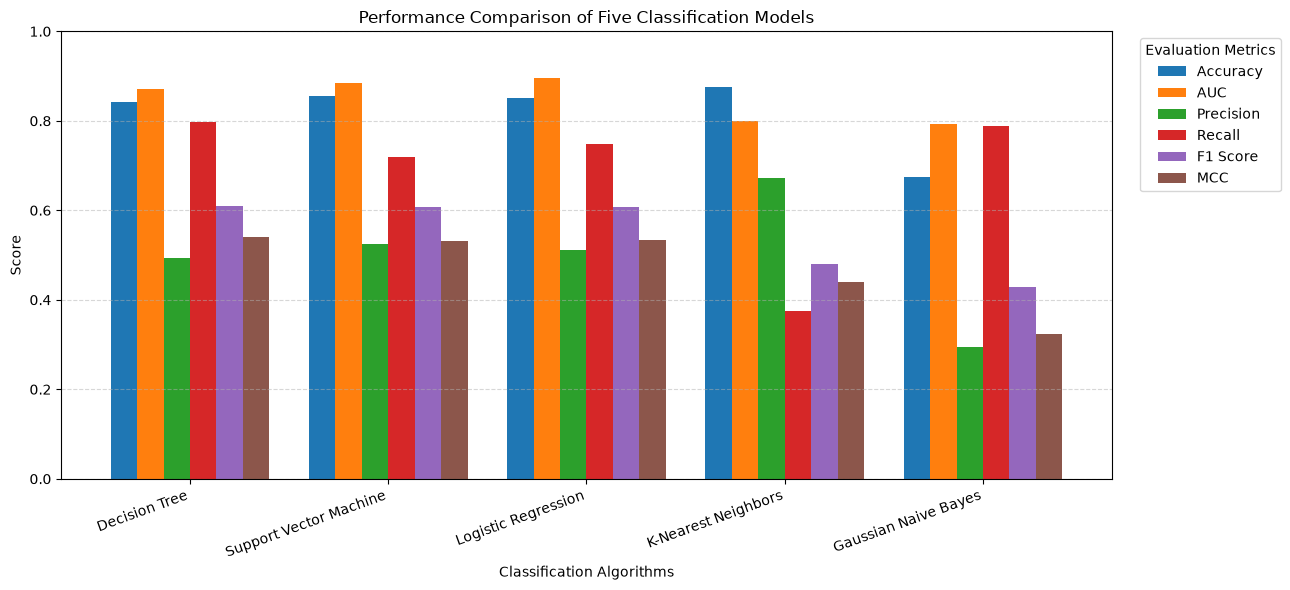

In [11]:
# Plot comparison of all five classification models
metrics_to_plot = [
    "Accuracy", "AUC", "Precision", "Recall", "F1 Score", "MCC"
]

comparison_df.set_index("Model")[metrics_to_plot].plot(
    kind="bar",
    figsize=(13, 6),
    width=0.8
)

plt.title("Performance Comparison of Five Classification Models")
plt.ylabel("Score")
plt.xlabel("Classification Algorithms")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.legend(title="Evaluation Metrics", bbox_to_anchor=(1.02, 1))
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

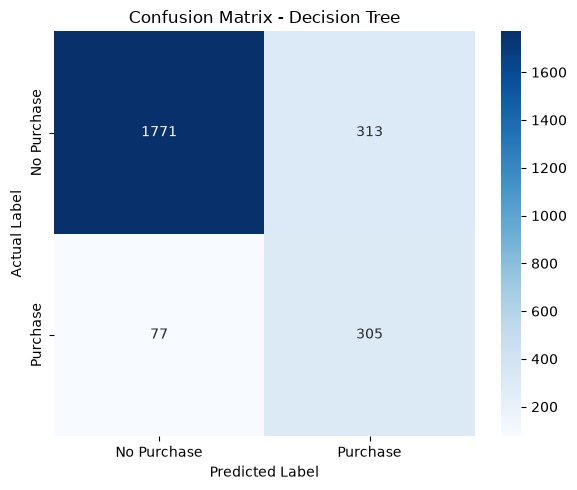

Classification Report:
              precision    recall  f1-score   support

 No Purchase       0.96      0.85      0.90      2084
    Purchase       0.49      0.80      0.61       382

    accuracy                           0.84      2466
   macro avg       0.73      0.82      0.76      2466
weighted avg       0.89      0.84      0.86      2466



In [12]:
# Select the best-performing model
best_pipeline = trained_models[best_model]

# Generate predictions
best_predictions = best_pipeline.predict(X_test)

# Calculate confusion matrix
cm = confusion_matrix(y_test, best_predictions)

# Plot confusion matrix
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Purchase", "Purchase"],
    yticklabels=["No Purchase", "Purchase"]
)

plt.title(f"Confusion Matrix - {best_model}")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

print("Classification Report:")
print(classification_report(
    y_test,
    best_predictions,
    target_names=["No Purchase", "Purchase"]
))

## Model Evaluation – Observations and Conclusion

### Individual Model Observations

1. **Logistic Regression:** Provides a balanced classification performance with good AUC and recall.

2. **Decision Tree:** Achieves good recall and identifies a substantial proportion of actual purchases.

3. **K-Nearest Neighbors (KNN):** Achieves high accuracy but has comparatively lower recall, indicating that it misses several actual purchases.

4. **Gaussian Naive Bayes:** Achieves high recall but low precision, resulting in more false-positive predictions.

5. **Support Vector Machine (SVM):** Demonstrates strong overall performance with competitive accuracy, AUC, F1 Score, and MCC.

### Overall Conclusion

Five classification algorithms were implemented and evaluated using the same training and testing datasets. Their performance was compared using Accuracy, AUC, Precision, Recall, F1 Score, and Matthews Correlation Coefficient (MCC).

The model with the highest F1 Score was selected as the overall best-performing classifier. This experiment demonstrates how different classification algorithms perform on imbalanced customer purchasing-intention data and highlights the importance of evaluating multiple metrics rather than relying on accuracy alone.